# 🧪 LAB: Classifying IoT Device Types with Machine Learning

**Motivation**: The rapid expansion of the Internet of Things (IoT) has dramatically increased the number and diversity of devices connected to modern networks. While these devices bring convenience and functionality, they also introduce new security vulnerabilities. In particular, the presence of unauthorized or malicious IoT devices within a network can pose a serious threat to organizational infrastructure.

To mitigate this risk, it is critical to develop tools that can automatically identify the type of IoT devices connected to a network based on their network traffic behavior. In this lab, you will explore this challenge by building and comparing machine learning models that classify IoT devices by type using real-world network data. 

To this end, in this lab you will be evaluating the effectiveness of different ensemble methods and reflecting on their performance. You will also compare these methods with neural network models.

**Dataset Description**: To do this lab, you will be working with a dataset that contains network traffic features collected from various Internet of Things (IoT) devices operating in a simulated smart home environment. The goal is to automatically identify the type of IoT device connected to the network based on its traffic behavior.

Problem Type: Multi-class classification — identifying which device type (e.g., camera, thermostat) corresponds to a given network traffic sample.

- Instances: 1,800 network traffic captures.

- Features: ~297 attributes per instance, including packet-level and flow-level statistics, protocol usage patterns, temporal and size-based features, categorical indicators (e.g., protocol types)

- Target Variable: device_category — class label indicating the type of IoT device (e.g., 'Light', 'Camera', 'Thermostat', etc.)

---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

--- 
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.


NAME(s) = "Chloe Wang, Ethan Ooi, Namitha Tholasi"

## Part 1: Data Preparation and Visualization (15 points)

In this part, you will prepare the data for modeling and explore it using dimensionality reduction techniques.

You should do the following:

1. **Load the data**  
   Load `iot_devices_train.csv` as the training dataset and `iot_devices_reporting.csv` as the reporting dataset.

2. **Separate inputs and outcomes**  
   - The outcome variable corresponds to the `"device_category"` column.  
   - Separate this column from the input features.

3. **Encode the outcome variable**  
   - The outcome variable (type of device) is currently a text variable.  
   - Convert it into numeric values so that each device type is assigned a unique number. Make sure device types are encoded correctly and consistently across the training and reporting sets.
   - *Hint:* You can use `LabelEncoder` from `scikit-learn` for this task.

4. **Dimensionality reduction for visualization**  
   - Apply both PCA and UMAP to reduce the dimensionality of the training set to two dimensions.  
   - Before applying PCA or UMAP, standardize the features. **IMPORTANT:** This standardization is only for the dimensionality reduction visualizations.  
   - Use **pipelines** to apply standardization followed by each dimensionality reduction method.

5. **Visualize the results**  
   - Create two scatter plots (one for PCA, one for UMAP) showing the 2D representations.  
   - Color each point according to its IoT device label.

6. **Compare the methods**  
   - Briefly discuss the differences between the PCA and UMAP visualizations.  
   - What patterns or separations can you observe? Which method seems to give better information about the structure in the data?


In [48]:
# 1.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
import umap

df_train = pd.read_csv("iot_devices_train.csv")
df_report = pd.read_csv("iot_devices_reporting.csv")

In [49]:
# 2.
X_train = df_train.drop(columns="device_category")
X_report = df_report.drop(columns="device_category")
y_train = df_train["device_category"]
y_report = df_report["device_category"]

In [50]:
# 3.
le = LabelEncoder()
y_train = le.fit_transform(y_train)
y_report = le.transform(y_report)
le.classes_

array(['TV', 'baby_monitor', 'lights', 'motion_sensor', 'security_camera',
       'smoke_detector', 'socket', 'thermostat', 'watch'], dtype=object)

In [51]:
# 4.
pca_pipe = Pipeline([("scaler", StandardScaler()), ("pca", PCA(n_components=2, random_state=1234))])
umap_pipe = Pipeline([("scaler", StandardScaler()), ("umap", umap.UMAP(n_components=2, random_state=1234))])

X_pca = pca_pipe.fit_transform(X_train)
X_umap = umap_pipe.fit_transform(X_train)

/opt/homebrew/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


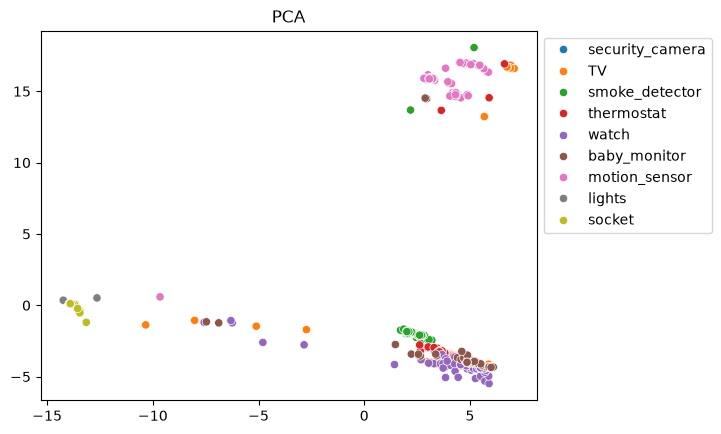

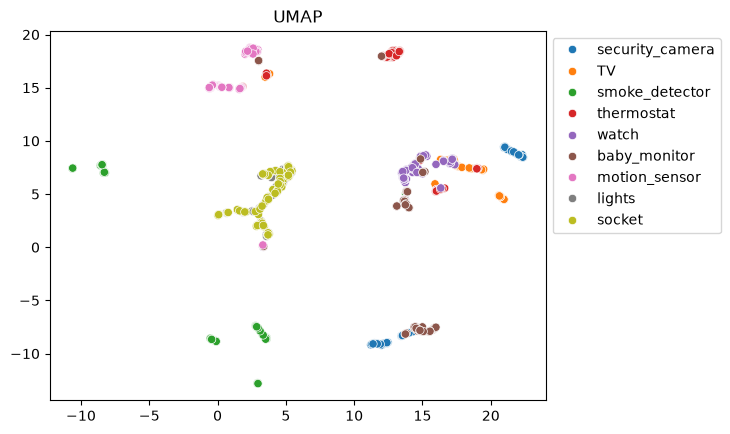

In [52]:
# 5.
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=le.inverse_transform(y_train))
plt.title("PCA")
plt.legend(bbox_to_anchor=(1, 1))
plt.show()

sns.scatterplot(x=X_umap[:, 0], y=X_umap[:, 1], hue=le.inverse_transform(y_train))
plt.title("UMAP")
plt.legend(bbox_to_anchor=(1, 1))
plt.show()

6. 
PCA basically squishes everything into 3 spots. Lights and sockets sit on top of each other on the left, motion sensors mostly get their own spot at the top, and everything else (cameras, watches, TVs, thermostats, baby monitors, smoke detectors) is piled together in the bottom right, so you can't really tell those apart.

UMAP splits the data into way more groups, and a lot of devices get their own tight clusters, like motion sensors, thermostats, and smoke detectors. Some still overlap though, like lights with sockets, security cameras with baby monitors, and watches with TVs.

So UMAP gives a lot better info about the structure here. That makes sense since PCA is linear and is only keeping the 2 directions with the most variance, while UMAP can pick up the non-linear patterns between devices.

## Part 2: Ensemble Methods with Scikit-Learn (40 points)

In this part, you will compare the performance of **Gradient Boosting** and **Random Forests** on the IoT device classification dataset.

Your tasks are:

1. **Pre-analysis Discussion and reflection**  
  Before starting, think about whether the typical preprocessing steps in machine learning (e.g., scaling, normalization, encoding) are necessary for tree-based ensemble methods such as Random Forests and Gradient Boosting. Write a brief explanation of which preprocessing steps (if any) you believe are required for these methods and why, and apply them only if you consider them necessary.

2. **Optimize each model**  
   Train and optimize both models using different combinations of the following hyperparameters:

   - Gradient Boosting: `max_depth`, `learning_rate`  
   - Random Forest: `max_depth`, `max_features`  

   *Tip:* Check the documentation of each model to understand what values make sense for these parameters.

   To ensure a fair comparison:
   - Use the same cross-validation object when optimizing both models.  
   - Use the same candidate values for `max_depth` across models.  
   - To keep the runtime manageable, test only THREE different values for each hyperparameter.  
   - Use a 5-fold cross-validation for tuning.

3. **Evaluate performance**  
   - Use each optimized model to evaluate performance on the reporting data.  
   - Report the accuracy and confusion matrix.
   - Report the total fitting time for the hyperparameter search. To measure it, record the time right before fitting the method and again immediately after it finishes. You can record the time using the `time()` function from the Python package `time`. Then, calculate the difference between the two to obtain the total training time (in minutes).
   - Discuss which types of devices are predicted most accurately and which are more difficult to classify.

4. **Analyze feature importance**  
   - Compare the feature importance resulting from each model. Do this both qualitatively and quantitatively (for example, by examining the similarity between feature importance vectors).
   - Are the most important features consistent across models? Which ones are these? Please, keep this discussion concise but thoughtful—focus on patterns and possible explanations rather than just listing numbers.
    
5. **Reflection**:  How do you think the models performed compared to random guessing?  *Hint:* A baseline accuracy of 50% assumes uniform random guessing between two categories. Since this is a multi-class problem, how should that baseline change?

1. No scaling or normalization is needed because trees split on one feature at a time, so the scale of a feature doesn't change where the split happens. Trees just need numeric inputs with no missing values, and our data already has that, so we don't need any preprocessing.

In [53]:
# 2.
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
from time import time

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1234)

param_grid_gb = {"max_depth": [3, 5, 10], "learning_rate": [0.01, 0.1, 1.0]}
param_grid_rf = {"max_depth": [3, 5, 10], "max_features": ["sqrt", "log2", 1.0]}

In [54]:
gb_grid = GridSearchCV(GradientBoostingClassifier(random_state=1234), param_grid_gb, cv=cv, scoring="accuracy", n_jobs=-1)

start = time()
gb_grid.fit(X_train, y_train)
gb_time = (time() - start) / 60

print(gb_grid.best_params_)
print(f"Search time: {gb_time:.2f} min")

{'learning_rate': 0.1, 'max_depth': 3}
Search time: 0.53 min


In [55]:
rf_grid = GridSearchCV(RandomForestClassifier(random_state=1234), param_grid_rf, cv=cv, scoring="accuracy", n_jobs=-1)

start = time()
rf_grid.fit(X_train, y_train)
rf_time = (time() - start) / 60

print(rf_grid.best_params_)
print(f"Search time: {rf_time:.2f} min")

{'max_depth': 10, 'max_features': 'log2'}
Search time: 0.03 min


   - Report the total fitting time for the hyperparameter search. To measure it, record the time right before fitting the method and again immediately after it finishes. You can record the time using the `time()` function from the Python package `time`. Then, calculate the difference between the two to obtain the total training time (in minutes).

The grid search took 0.53 min for GB vs. 0.03 min for RF, a difference of .50 min (~30sec).

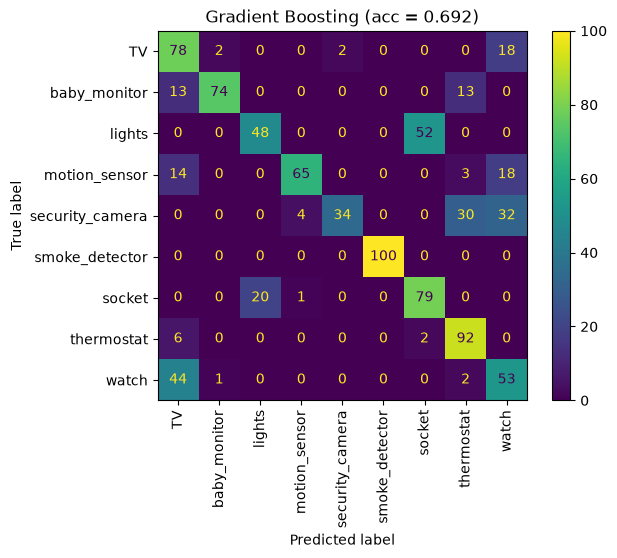

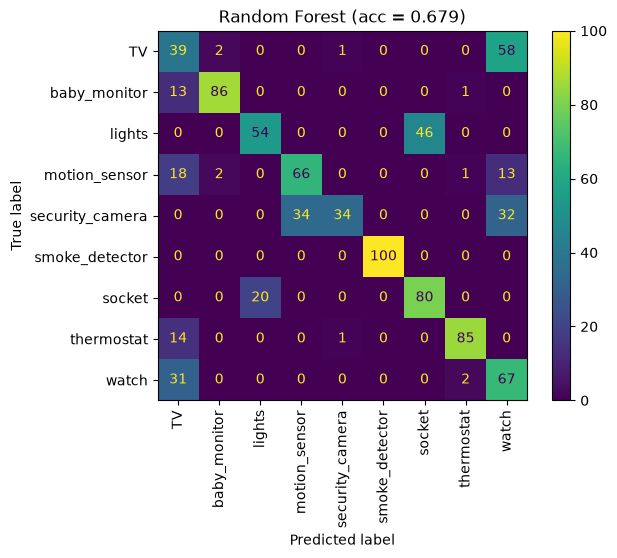

In [56]:
# 3.
for name, grid in [("Gradient Boosting", gb_grid), ("Random Forest", rf_grid)]:
    y_pred = grid.predict(X_report)
    ConfusionMatrixDisplay.from_predictions(y_report, y_pred, display_labels=le.classes_, xticks_rotation=90)
    plt.title(f"{name} (acc = {accuracy_score(y_report, y_pred):.3f})")
    plt.show()

 - Discuss which types of devices are predicted most accurately and which are more difficult to classify.

Both models get smoke detectors 100% right, and thermostats, sockets, and baby monitors are pretty good too. The hardest ones are security cameras (only 34 right in both), lights which get mixed up with sockets, and TVs and watches which get mixed up with each other. That kind of matches the UMAP plot from Part 1 where those same devices were overlapping.

In [57]:
# 4.
importances = pd.DataFrame({
    "GB": gb_grid.best_estimator_.feature_importances_,
    "RF": rf_grid.best_estimator_.feature_importances_,
}, index=X_train.columns)

print(importances["GB"].sort_values(ascending=False).head(10))
print(importances["RF"].sort_values(ascending=False).head(10))

ttl_avg                          0.094893
packet_inter_arrivel_min         0.065986
packet_inter_arrivel_sum         0.057496
packet_inter_arrivel_B_min       0.057185
packet_inter_arrivel_firstQ      0.053107
packet_inter_arrivel_A_sum       0.051111
ttl_min                          0.050548
ttl_entropy                      0.049869
packet_inter_arrivel_A_thirdQ    0.037485
http_time_thirdQ                 0.033227
Name: GB, dtype: float64
ttl_B_max                     0.028559
ttl_B_min                     0.028310
packet_inter_arrivel_sum      0.021797
ttl_max                       0.021570
ttl_avg                       0.020717
ttl_min                       0.018882
packet_inter_arrivel_A_max    0.018428
ttl_B_median                  0.018370
packet_inter_arrivel_var      0.017663
packet_inter_arrivel_min      0.017356
Name: RF, dtype: float64


In [58]:
from sklearn.metrics.pairwise import cosine_similarity

top_gb = importances["GB"].sort_values(ascending=False).head(10).index
top_rf = importances["RF"].sort_values(ascending=False).head(10).index

print("Cosine similarity:", cosine_similarity([importances["GB"]], [importances["RF"]])[0, 0])
print("Shared top 10 features:", list(top_gb.intersection(top_rf)))

Cosine similarity: 0.6449880623208164
Shared top 10 features: ['ttl_avg', 'packet_inter_arrivel_min', 'packet_inter_arrivel_sum', 'ttl_min']


4. 
Both models mostly care about the same kinds of features, which are the TTL features (ttl_avg, ttl_min, ttl_max) and the packet inter-arrival time features. 4 of the top 10 are the exact same features, and the rest are mostly other TTL and inter-arrival ones.

The cosine similarity is only .64 though, since GB puts a lot of weight on a few features (ttl_avg is about .09) while RF spreads it out more (its top one is about .03). This makes sense since inter-arrival time shows how often a device sends traffic, like a camera streaming all the time vs. a smoke detector that barely sends anything.

5. 
With 9 balanced device types, random guessing would only get about 1/9 = 11% right, not 50%. Both models got around 68-69%, so they're doing about 6x better than random guessing. So even though they mix up some devices, they're definitely learning real patterns from the traffic.

## Part 3: Histogram-Based Gradient Boosting (20 points)

Gradient Boosting is a powerful algorithm, but it can also be computationally expensive. To address this limitation, a modern and optimized implementation inspired by *LightGBM* has been introduced (see recommended reading). In `scikit-learn`, this approach is available through `HistGradientBoostingClassifier`.

Here, you will explore how this implementation differs from the traditional `GradientBoostingClassifier`, understand the mechanisms behind its computational efficiency, and apply it to the same dataset used previously.

You should complete the following steps:

1. **Read and summarize**  
   Read the [Histogram-based Gradient Boosting documentation](https://scikit-learn.org/stable/modules/ensemble.html#histogram-based-gradient-boosting), which describes the algorithm and its key differences from `GradientBoostingClassifier`.  

   *Optional (for deeper understanding):*
   - Ke et al. (2017). *[LightGBM: A Highly Efficient Gradient Boosting Decision Tree](https://proceedings.neurips.cc/paper_files/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html)*  
   - *[Introduction to Boosted Trees — XGBoost documentation](https://xgboost.readthedocs.io/en/stable/tutorials/model.html)*  

   Then, briefly answer the following questions:  
   - What are the main differences between `HistGradientBoostingClassifier` and `GradientBoostingClassifier`?  
   - How does histogram binning make training faster?

2. **Optimize and train a `HistGradientBoostingClassifier` object from `sklearn.ensemble`**  
   - Use the same approach you applied to Gradient Boosting in Part 2.  
   - Reuse the same `param_grid` from Part 2.  
   - Use `GridSearchCV` for hyperparameter tuning.  
   - Use the same cross-validation object to ensure a fair comparison.

3. **Evaluate the optimized model**  
   - Report the accuracy and confusion matrix.
   - Measure and report the total hyperparameter search time, following the same procedure used in Part 2.
4. **Reflection**  
   - How does this method compare to `GradientBoostingClassifier` in terms of computation time and predictive performance? Discuss any trade-offs you observe.

1. 
 - What are the main differences between `HistGradientBoostingClassifier` and `GradientBoostingClassifier`?

HistGradientBoosting first puts every feature into at most 255 bins, so the trees split on bins instead of the exact values. It also handles missing values and categorical features on its own, uses multiple cores, and the docs say it's way faster once the data gets to tens of thousands of samples.

 - How does histogram binning make training faster?

Regular GB has to sort each feature and check basically every possible split point, which gets slow with a lot of unique values. With binning it only has to check at most 255 split points per feature, so finding the best split is way quicker.

In [59]:
# 2.
from sklearn.ensemble import HistGradientBoostingClassifier

hgb_grid = GridSearchCV(HistGradientBoostingClassifier(random_state=1234), param_grid_gb, cv=cv, scoring="accuracy", n_jobs=-1)

start = time()
hgb_grid.fit(X_train, y_train)
hgb_time = (time() - start) / 60

print(hgb_grid.best_params_)
print(f"Search time: {hgb_time:.2f} min")

{'learning_rate': 0.1, 'max_depth': 3}
Search time: 0.24 min


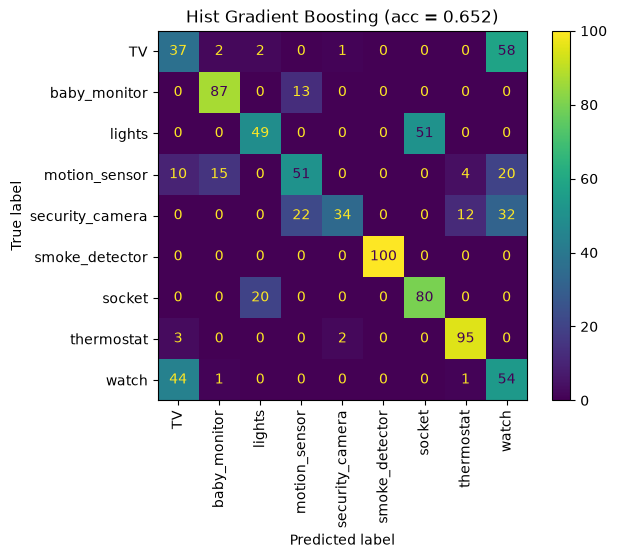

In [60]:
# 3.
y_pred = hgb_grid.predict(X_report)
ConfusionMatrixDisplay.from_predictions(y_report, y_pred, display_labels=le.classes_, xticks_rotation=90)
plt.title(f"Hist Gradient Boosting (acc = {accuracy_score(y_report, y_pred):.3f})")
plt.show()

3. 
HistGradientBoosting picked the same params as regular GB (learning_rate = .1, max_depth = 3) and got .652 accuracy on the reporting set. Like the other models, smoke detectors and thermostats are the easiest, while TVs get mixed up with watches and lights get mixed up with sockets.

4. 
HistGradientBoosting was about 2x faster than regular GB (0.24 min vs. 0.53 min), but it did a bit worse on the reporting set, .652 vs. .692. The speedup isn't as big as the docs make it sound because we only have 900 rows, and most of our features only have a few unique values anyway, so binning them into 255 bins doesn't really save much.

The drop in accuracy is mostly from TVs (37 right vs. 78) and motion sensors (51 vs. 65). So the trade-off is speed vs. a little accuracy, and for data this small regular GB is fine, but on way bigger data HistGB would be better.

## Part 4: Neural Network Model (20 points)

In this final part of the assignment, you will revisit neural networks and compare their performance with the ensemble methods explored in the previous parts.

You should do the following:

1. **Preprocessing reflection**  
   - Briefly describe which preprocessing steps are important before training a neural network.  
   - If such steps are necessary in this case, apply them before training your model.

2. **Model optimization and training**  
   - Use NINE different combinations of hidden units and hidden layers as the hyperparameters to tune.
   - Use early stopping to reduce the risk of overfitting.  
   - Train the model for up to 300 epochs.  
   - Use `GridSearchCV` to optimize the model’s hyperparameters.  
   - Make sure to use the same cross-validation object as in Parts 2 and 3 for a fair comparison.  
   - *Tip:* Check the [MLPClassifier documentation](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html) to see how to enable early stopping and adjust other parameters.

3. **Evaluate performance**  
   - Use the same evaluation metrics as in Parts 2 and 3.  
   - Compare the neural network’s performance with the ensemble models.  
   - Reflect on how model complexity and interpretability differ across methods.

**Constraint:**  
Use `MLPClassifier` from `scikit-learn` for this exercise.


1. 
 - Briefly describe which preprocessing steps are important before training a neural network.

Unlike trees, neural networks care about the scale of the features since every input gets multiplied by a weight and the gradients depend on how big the values are. Our features are on super different scales, so we need to standardize them or the big ones would basically take over and training would be slow and unstable. The inputs also have to be numeric and the outcome has to be encoded, but we already did that in Part 1.


In [61]:
# 2.
from sklearn.neural_network import MLPClassifier

mlp_pipe = Pipeline([("scaler", StandardScaler()), ("mlp", MLPClassifier(early_stopping=True, max_iter=300, random_state=1234))])

param_grid_mlp = {"mlp__hidden_layer_sizes": [(32,), (64,), (128,),
                                              (32, 32), (64, 64), (128, 128),
                                              (32, 32, 32), (64, 64, 64), (128, 128, 128)]}

mlp_grid = GridSearchCV(mlp_pipe, param_grid_mlp, cv=cv, scoring="accuracy", n_jobs=-1)

start = time()
mlp_grid.fit(X_train, y_train)
mlp_time = (time() - start) / 60

print(mlp_grid.best_params_)
print(f"Search time: {mlp_time:.2f} min")

{'mlp__hidden_layer_sizes': (128, 128, 128)}
Search time: 0.02 min


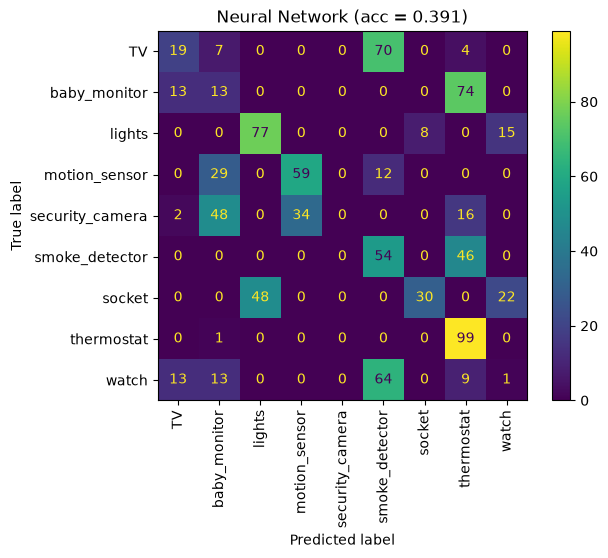

In [62]:
# 3.
y_pred = mlp_grid.predict(X_report)
ConfusionMatrixDisplay.from_predictions(y_report, y_pred, display_labels=le.classes_, xticks_rotation=90)
plt.title(f"Neural Network (acc = {accuracy_score(y_report, y_pred):.3f})")
plt.show()

3. 

 - Compare the neural network's performance with the ensemble models.

The NN only got .391 on the reporting set, way worse than all the ensembles (.692 GB, .679 RF, .652 HistGB). This is because a lot of features barely change in the training data but have huge values in the reporting data, so standardizing blows them up and throws off the network, while trees don't care.

 - Reflect on how model complexity and interpretability differ across methods.

The NN is the most complex and there's no easy way to see why it predicted something, while the ensembles still give us feature importance. So for this data the ensembles were more accurate and easier to explain.

## Part 5: Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

**We didn't run into any major problems this lab. One thing we could improve is checking the training and reporting data side by side before modeling, since we only found out late in Part 4 that some features had way bigger values in the reporting data.**